In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Задамо коефіцієнти. Мій варіант - 7


In [ ]:
true_theta = np.loadtxt("coefficients.txt")

In [ ]:
true_theta

array([0.  , 0.33, 0.15, 0.11, 0.5 , 0.  , 0.5 ])

In [ ]:
a0, a1, a2, a3, b1, b2, b3 = true_theta

Завантажимо білий шум із файлу v.txt



In [ ]:
v = np.loadtxt("v.txt")

Завантажимо значення для y із файлу y.txt:


In [ ]:
y = np.loadtxt("y.txt")

Визначимо к-сть спостережень:







In [ ]:
N = len(y)

Отже, наш датасет:


In [ ]:
data = pd.DataFrame({
    "k":np.arange(N),
    "v": v,
    "y":y
}
)

In [ ]:
data.head()

,k,v,y
0,0,0.304717,0.304717
1,1,-1.039984,-1.039984
2,2,0.750451,0.750451
3,3,0.940565,1.593319
4,4,-1.951035,-1.476780


Створимо функцію яка буде оцінювати різні моделі від АРКС(1,1) до АРКС(3,3)

In [ ]:
def build_matrix(y,v,p,q):
  X=[]
  Y=[]
  start = max(p,q)

  for k in range(start, len(y)):
    row=[1] # 1-й елемент кожного рядку це 1 бо це коефіцієнт біля a0

    #AR частина: y(k-1)...y(k-p)
    for i in range(1,p+1):
      row.append(y[k-i])

    #MA частина: v(k-1)...v(k-q)
    for j in range(1,q+1):
      row.append(v[k-j])

    X.append(row)

    Y.append(y[k] - v[k])

  return np.array(X), np.array(Y)



**МНК**

In [ ]:
# створимо функцію для МНКц
def ols(X,Y):
  try:
    theta_hat = np.linalg.inv(X.T @ X) @ X.T @ Y
    return theta_hat

  except np.linalg.LinAlgError:
    return None


**Метрики**


In [ ]:
def calculate_metrics(Y, Y_hat, y_hat, y_actual, number_of_parameters):
  errors = Y-Y_hat

  #Сума квадратів похибок
  S = np.sum(errors**2)

  #R^2
  R2 = np.var(y_hat) / np.var(y_actual)

  #АІС  Akaike information criterion
  N = len(Y)

  AIC = N * np.log(S) + 2*number_of_parameters


  return S, R2, AIC

Оцінювання АРКС:


In [ ]:
def fit_arks(y,v,p,q):
  # матриці X та Y
  X,Y = build_matrix(y,v,p,q)

  # МНК
  theta_hat = ols(X,Y)

  #Прогноз моделі
  Y_hat = X @ theta_hat
  #
  max_lag = max(p, q)
  y_hat = Y_hat + v[max_lag:]  #Y_hat - v + v = Y_hat
  y_actual = y[max_lag:] # наші оригінальні вимірювання

  #К-сть оцінюваних параметрів для AIC
  # a0 + p параметрів + q параметрів
  number_of_parameters = 1+p+q

  # наші метрики: S, R_2, AIC
  S, R2, AIC = calculate_metrics(Y,Y_hat,y_hat,y_actual, number_of_parameters)

  return {
        "p": p,
        "q": q,
        "theta": theta_hat,
        "S": S,
        "R2": R2,
        "AIC": AIC,
        "Y": Y,
        "Y_hat": Y_hat
    }


Тепер всі 9 модель через МНК

In [ ]:
results = []

for p in range(1,4):
  for q in range(1,4):

    result = fit_arks(y,v,p,q)
    results.append(result)


Виведемо результати для МНК

In [ ]:
results_table = []

for result in results:

    p = result["p"]
    q = result["q"]

    theta = result["theta"]

    results_table.append({
        "Model": f"ARKS({p},{q})",
        "S": result["S"],
        "R2": result["R2"],
        "AIC": result["AIC"],
        "theta": theta
    })


results_df = pd.DataFrame(results_table)

In [ ]:
pd.set_option('display.float_format', '{:.6f}'.format)
results_df

,Model,S,R2,AIC,theta
0,"ARKS(1,1)",21.214401,0.894797,308.413344,"[-0.00479758989926464, 0.7140849524053188, 0.1..."
1,"ARKS(1,2)",20.003562,0.898503,301.599216,"[-0.005604376253183475, 0.7939852797397486, 0...."
2,"ARKS(1,3)",0.899416,1.005357,-0.282964,"[0.0014729151498720033, 0.570521406426667, 0.2..."
3,"ARKS(2,1)",13.721974,0.925883,264.661850,"[0.0012369142083593562, 0.19081538417942348, 0..."
4,"ARKS(2,2)",10.864526,0.931151,243.779293,"[-0.00372742052064573, 0.24886358065383107, 0...."
5,"ARKS(2,3)",0.188279,1.003987,-149.973411,"[0.0005220420888969973, 0.4188974538789854, 0...."
6,"ARKS(3,1)",7.111120,0.945436,200.280994,"[-0.011755776061790416, 0.04948026501979244, 0..."
7,"ARKS(3,2)",6.813376,0.944500,198.132115,"[-0.010352480854455549, -0.032826252775928426,..."
8,"ARKS(3,3)",0.000000,1.000000,-4148.341145,"[-5.418161412109963e-12, 0.32999999997115664, ..."


Виведемо коефіцієнти кожної моделі

In [ ]:

for result in results:

    p = result["p"]
    q = result["q"]

    theta = result["theta"]

    print()
    print("#" * 50)
    print(f"МНК - АРКС({p},{q})")
    print("=" * 50)

    index = 0

    print(f"a0 = {theta[index]:.6f}")

    index += 1

    # a1 ... ap
    for i in range(1, p + 1):

        print(f"a{i} = {theta[index]:.6f}")

        index += 1

    # b1 ... bq
    for j in range(1, q + 1):

        print(f"b{j} = {theta[index]:.6f}")

        index += 1

    print(f"S   = {result['S']:.6f}")
    print(f"R2  = {result['R2']:.6f}")
    print(f"AIC = {result['AIC']:.6f}")



##################################################
МНК - АРКС(1,1)
a0 = -0.004798
a1 = 0.714085
b1 = 0.101939
S   = 21.214401
R2  = 0.894797
AIC = 308.413344

##################################################
МНК - АРКС(1,2)
a0 = -0.005604
a1 = 0.793985
b1 = 0.041851
b2 = -0.176429
S   = 20.003562
R2  = 0.898503
AIC = 301.599216

##################################################
МНК - АРКС(1,3)
a0 = 0.001473
a1 = 0.570521
b1 = 0.251243
b2 = -0.056286
b3 = 0.614496
S   = 0.899416
R2  = 1.005357
AIC = -0.282964

##################################################
МНК - АРКС(2,1)
a0 = 0.001237
a1 = 0.190815
a2 = 0.491807
b1 = 0.616892
S   = 13.721974
R2  = 0.925883
AIC = 264.661850

##################################################
МНК - АРКС(2,2)
a0 = -0.003727
a1 = 0.248864
a2 = 0.558101
b1 = 0.587127
b2 = -0.284523
S   = 10.864526
R2  = 0.931151
AIC = 243.779293

##################################################
МНК - АРКС(2,3)
a0 = 0.000522
a1 = 0.418897
a2 = 0.183980
b1 = 0.40596

Побудуємо графіки для наглядності результів

ДЛЯ S:


In [ ]:
model_names = []
for row in results_table:
  model_names.append(row['Model'])

In [ ]:
S_values = []
for row in results_table:
  S_values.append(row["S"])


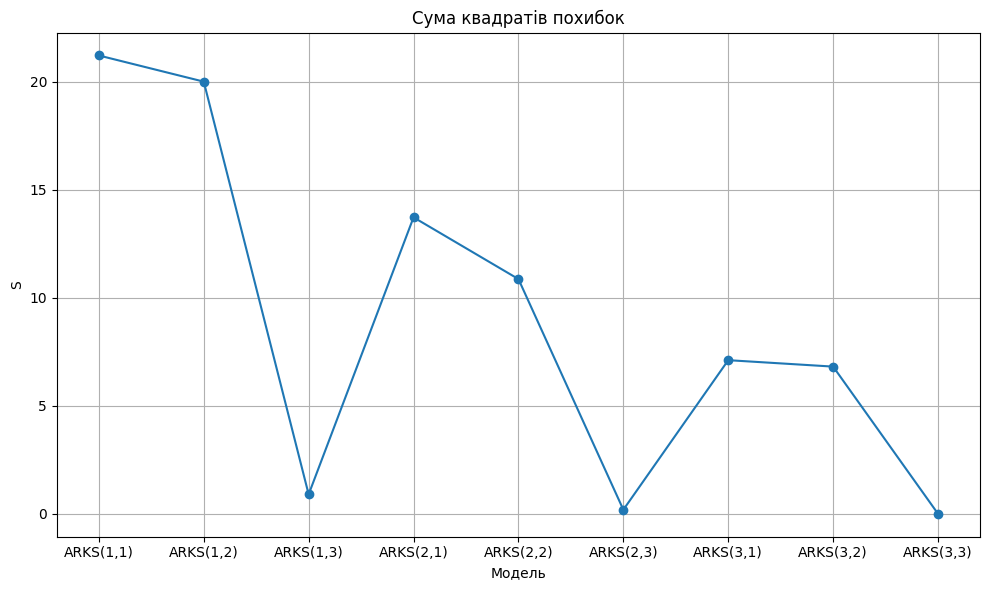

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    model_names,
    S_values,
     marker="o"
)
plt.xlabel("Модель")
plt.ylabel("S")
plt.title("Сума квадратів похибок")

plt.grid()

plt.tight_layout()

plt.show()

Для R^2:

In [ ]:
R2_values = []
for result in results:
  R2_values.append(result["R2"])

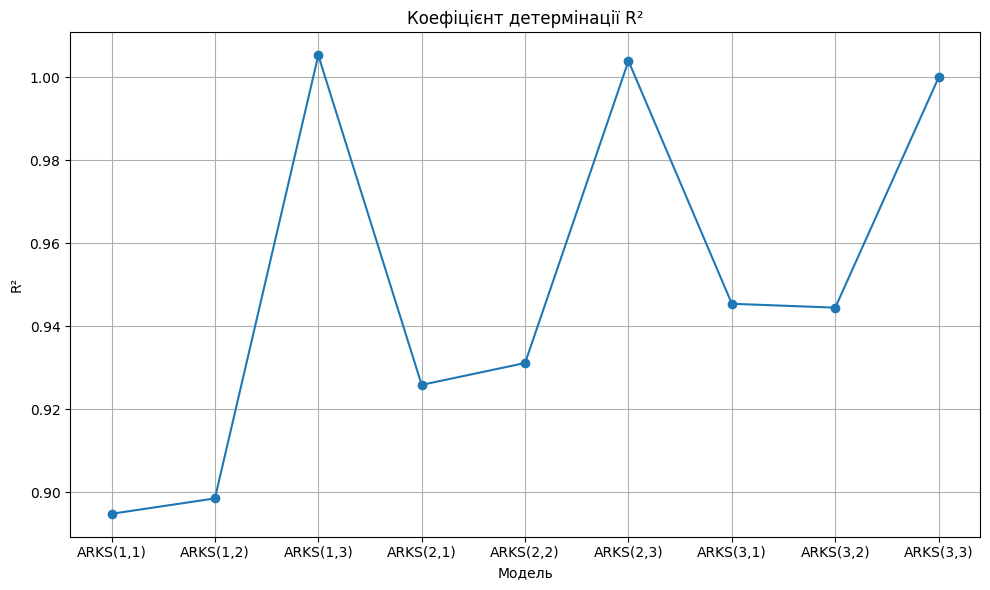

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    model_names,
    R2_values,
    marker="o"
)

plt.xlabel("Модель")
plt.ylabel("R²")
plt.title("Коефіцієнт детермінації R²")


plt.grid()

plt.tight_layout()

plt.show()

Для AIC:

In [ ]:
AIC_values = []
for result in results:
  AIC_values.append(result["AIC"])

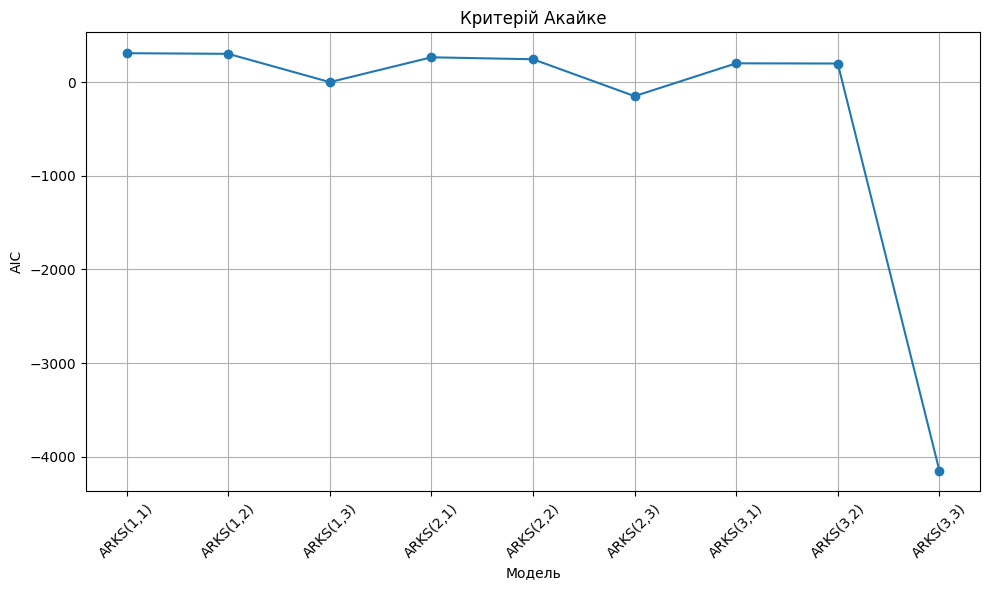

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(
    model_names,
    AIC_values,
    marker="o"
)

plt.xlabel("Модель")
plt.ylabel("AIC")
plt.title("Критерій Акайке")

plt.xticks(rotation=45)

plt.grid()

plt.tight_layout()

plt.show()

Знайдемо модель із мінімальним АІС

In [ ]:

best_model = min(
    results,
    key=lambda x: x["AIC"]
)

print("\nМодель з мінімальним AIC:")

print(f"АРКС({best_model['p']},{best_model['q']})")

print("AIC =",best_model["AIC"])

print("S =",best_model["S"])

print("R2 =",best_model["R2"])

print("theta =",best_model["theta"])


Модель з мінімальним AIC:
АРКС(3,3)
AIC = -4148.34114486322
S = 2.312625165794645e-19
R2 = 1.000000000008551
theta = [-5.41816141e-12  3.30000000e-01  1.50000000e-01  1.10000000e-01
  5.00000000e-01  2.45954114e-11  5.00000000e-01]


ТЕПЕР РМНК

функція РМНК

In [ ]:
def rls(X,Y, beta=10):
  n_parameters=X.shape[1] # к-сть спостережень

  # початкові оцінки параметрів
  theta = np.zeros(n_parameters)

  #P0 = beta*I де beta>>0
  # eye - Return a 2-D array with ones on the diagonal and zeros elsewhere.
  P = beta * np.eye(n_parameters)

  #список для зберігання theta після кожної ітерації
  theta_history=[]
  for k in range(len(Y)):
    x=X[k]

    #Оновлення матриці P
    # ініціалізуємо знаменник окремо
    denominator = 1 + x @ P @ x.T
    numerator = P @ np.outer(x, x) @ P
    P_new = P - numerator / denominator

    #поточний прогноз
    y_hat = x @ theta

    #помилка прогнозу
    error = Y[k] - y_hat

    #тепер оновлення theta:
    # theta = theta + P_new @ x.T @ (Y[k].T-x @ theta)
    theta = theta + P_new @ x.T * error

    #зберігаємо theta для  майбутніх графіків зі збіжності
    theta_history.append(theta.copy())

    #переходимо до наступної ітерації
    P = P_new

  return theta, np.array(theta_history)



In [ ]:
def fit_arks_rls(y,v,p,q, beta=10.0):
  X,Y = build_matrix(y,v,p,q)

  theta_hat, theta_history = rls(X,Y,beta)

  Y_hat = X @ theta_hat

  #к-сть параметрів
  number_of_parameters = 1 + p + q

  # з якого моменту часу
  max_lag = max(p, q)
  # повертаємо y_hat без v(k)
  y_hat = Y_hat + v[max_lag:]  #
  y_actual = y[max_lag:]


  #метрики
  S, R2, AIC = calculate_metrics(Y,Y_hat,y_hat,y_actual, number_of_parameters)

  return {
        "p": p,
        "q": q,
        "theta": theta_hat,
        "theta_history": theta_history,
        "S": S,
        "R2": R2,
        "AIC": AIC,
        "Y": Y,
        "Y_hat": Y_hat
    }


Проганяємо всі 9 моделей через РМНК

In [ ]:
r_results = []
for p in range(1,4):
  for q in range(1,4):
    result = fit_arks_rls(y,v,p,q,beta=10)

    r_results.append(result)

Заповнюємо таблицю

In [ ]:
r_table = []

for result in r_results:
  p = result["p"]
  q = result["q"]
  r_table.append({
      "Model": f"ARKS({p},{q})",
      "S": result["S"],
      "R2": result["R2"],
      "AIC": result["AIC"],
      "theta": result["theta"]
  })
r_df = pd.DataFrame(r_table)


In [ ]:
r_df.head()

,Model,S,R2,AIC,theta
0,"ARKS(1,1)",21.214439,0.894197,308.413521,"[-0.004829838920499803, 0.7134976199481936, 0...."
1,"ARKS(1,2)",20.003689,0.897789,301.599838,"[-0.005612148918298668, 0.7926346303431758, 0...."
2,"ARKS(1,3)",0.899497,1.004467,-0.274192,"[0.001428485536544713, 0.5702871753044662, 0.2..."
3,"ARKS(2,1)",13.722328,0.925126,264.664381,"[0.0011866458141712073, 0.19437731137516967, 0..."
4,"ARKS(2,2)",10.864900,0.930279,243.782662,"[-0.0037540492433890548, 0.2520209568710178, 0..."


Виведемо коефіцієнти РМНК

In [ ]:
for result in r_results:

    p = result["p"]
    q = result["q"]
    theta = result["theta"]

    print()
    print("=" * 50)
    print(f"РМНК - АРКС({p},{q})")
    print("=" * 50)

    index = 0

    print(f"a0 = {theta[index]:.6f}")
    index += 1

    for i in range(1, p + 1):
        print(f"a{i} = {theta[index]:.6f}")
        index += 1

    for j in range(1, q + 1):
        print(f"b{j} = {theta[index]:.6f}")
        index += 1

    print(f"S   = {result['S']:.6f}")
    print(f"R2  = {result['R2']:.6f}")
    print(f"AIC = {result['AIC']:.6f}")


РМНК - АРКС(1,1)
a0 = -0.004830
a1 = 0.713498
b1 = 0.102324
S   = 21.214439
R2  = 0.894197
AIC = 308.413521

РМНК - АРКС(1,2)
a0 = -0.005612
a1 = 0.792635
b1 = 0.042948
b2 = -0.175026
S   = 20.003689
R2  = 0.897789
AIC = 301.599838

РМНК - АРКС(1,3)
a0 = 0.001428
a1 = 0.570287
b1 = 0.251009
b2 = -0.055874
b3 = 0.613522
S   = 0.899497
R2  = 1.004467
AIC = -0.274192

РМНК - АРКС(2,1)
a0 = 0.001187
a1 = 0.194377
a2 = 0.488808
b1 = 0.612367
S   = 13.722328
R2  = 0.925126
AIC = 264.664381

РМНК - АРКС(2,2)
a0 = -0.003754
a1 = 0.252021
a2 = 0.554921
b1 = 0.582938
b2 = -0.283381
S   = 10.864900
R2  = 0.930279
AIC = 243.782662

РМНК - АРКС(2,3)
a0 = 0.000478
a1 = 0.418996
a2 = 0.184042
b1 = 0.405165
b2 = -0.107451
b3 = 0.537286
S   = 0.188364
R2  = 1.003172
AIC = -149.929685

РМНК - АРКС(3,1)
a0 = -0.011775
a1 = 0.054750
a2 = 0.388075
a3 = 0.312639
b1 = 0.809505
S   = 7.111803
R2  = 0.944459
AIC = 200.290311

РМНК - АРКС(3,2)
a0 = -0.010423
a1 = -0.023658
a2 = 0.323226
a3 = 0.409684
b1 = 0.88

Тепер порівняймо результати МНК і РМНК:

In [ ]:
comparison_table = []

for result, r_result in zip(results, r_results): # zip - проходимо парами

    p = result["p"]
    q = result["q"]

    comparison_table.append({
        "Model": f"ARKS({p},{q})",

        "S": result["S"],
        "R2": result["R2"],
        "AIC": result["AIC"],

        "R S": r_result["S"],
        "R R2": r_result["R2"],
        "R AIC": r_result["AIC"]
    })# R - означає Recursive

comparison_df = pd.DataFrame(comparison_table)

In [ ]:
comparison_df

,Model,S,R2,AIC,R S,R R2,R AIC
0,"ARKS(1,1)",21.214401,0.894797,308.413344,21.214439,0.894197,308.413521
1,"ARKS(1,2)",20.003562,0.898503,301.599216,20.003689,0.897789,301.599838
2,"ARKS(1,3)",0.899416,1.005357,-0.282964,0.899497,1.004467,-0.274192
3,"ARKS(2,1)",13.721974,0.925883,264.661850,13.722328,0.925126,264.664381
4,"ARKS(2,2)",10.864526,0.931151,243.779293,10.864900,0.930279,243.782662
5,"ARKS(2,3)",0.188279,1.003987,-149.973411,0.188364,1.003172,-149.929685
6,"ARKS(3,1)",7.111120,0.945436,200.280994,7.111803,0.944459,200.290311
7,"ARKS(3,2)",6.813376,0.944500,198.132115,6.814700,0.943442,198.150956
8,"ARKS(3,3)",0.000000,1.000000,-4148.341145,0.000110,0.999224,-870.516425


In [ ]:
def ols_history(X, Y): # ols - ordinary least squares - мнк
    theta_history = []
    k_history = []

    n_parameters = X.shape[1]

    for k in range(n_parameters, len(Y) + 1):

        X_k = X[:k]
        Y_k = Y[:k]

        try:
            theta_hat = (
                np.linalg.inv(X_k.T @ X_k)
                @ X_k.T
                @ Y_k
            )

            theta_history.append(theta_hat)
            k_history.append(k)
        # якщо матриця вироджена (визначник = 0), не можливо знайти обернену. тоді:
        except np.linalg.LinAlgError:
            continue

    return np.array(theta_history), np.array(k_history)

In [ ]:
def fit_arks(y, v, p, q):

    X, Y = build_matrix(y, v, p, q)

    theta_hat = ols(X, Y)

    theta_history, k_history = ols_history(X, Y)

    Y_hat = X @ theta_hat

    #
    max_lag = max(p, q)
    y_hat = Y_hat + v[max_lag:]  #Y_hat - v + v = Y_hat
    y_actual = y[max_lag:] # наші оригінальні вимірювання

    #К-сть оцінюваних параметрів
    number_of_parameters = 1+p+q

    S, R2, AIC = calculate_metrics(
        Y,
        Y_hat,
        y_hat,
        y_actual,
        number_of_parameters
    )

    return {
        "p": p,
        "q": q,
        "theta": theta_hat,
        "theta_history": theta_history,
        "k_history": k_history,
        "S": S,
        "R2": R2,
        "AIC": AIC,
        "Y": Y,
        "Y_hat": Y_hat
    }

In [ ]:
results = []

for p in range(1, 4):
    for q in range(1, 4):

        result = fit_arks(
            y,
            v,
            p,
            q
        )

        results.append(result)

In [ ]:
parameter_names = [
    "a0",
    "a1",
    "a2",
    "a3",
    "b1",
    "b2",
    "b3"
]

In [ ]:
ols_22 = next(
    r for r in results
    if r["p"] == 2 and r["q"] == 2
)

rls_22 = next(
    r for r in r_results
    if r["p"] == 2 and r["q"] == 2
)

parameter_names_22 = [
    "a0",
    "a1",
    "a2",
    "b1",
    "b2"
]

true_theta_22 = np.array([
    0.0,
    0.33,
    0.15,
    0.5,
    0.0
])

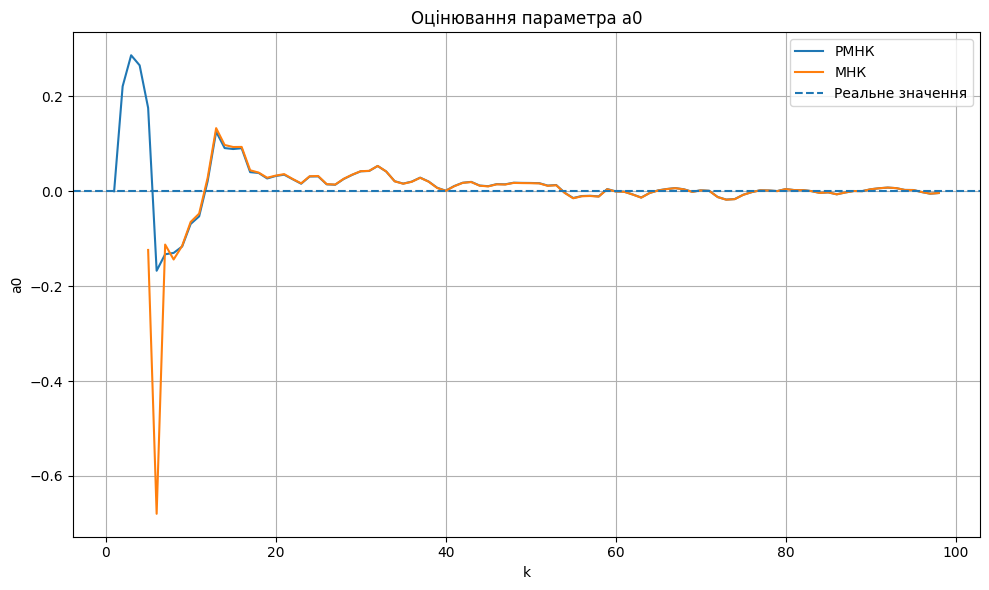

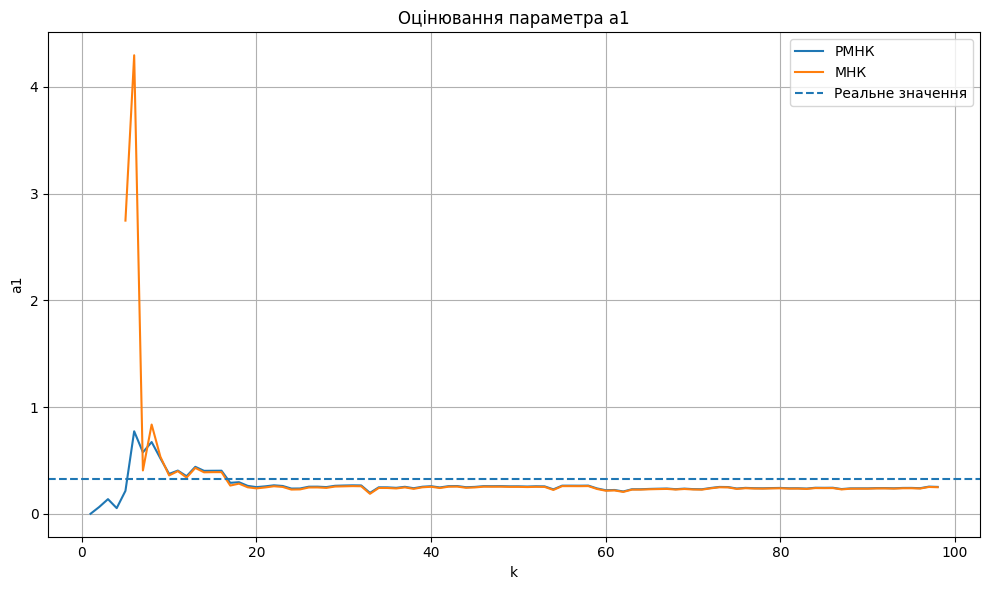

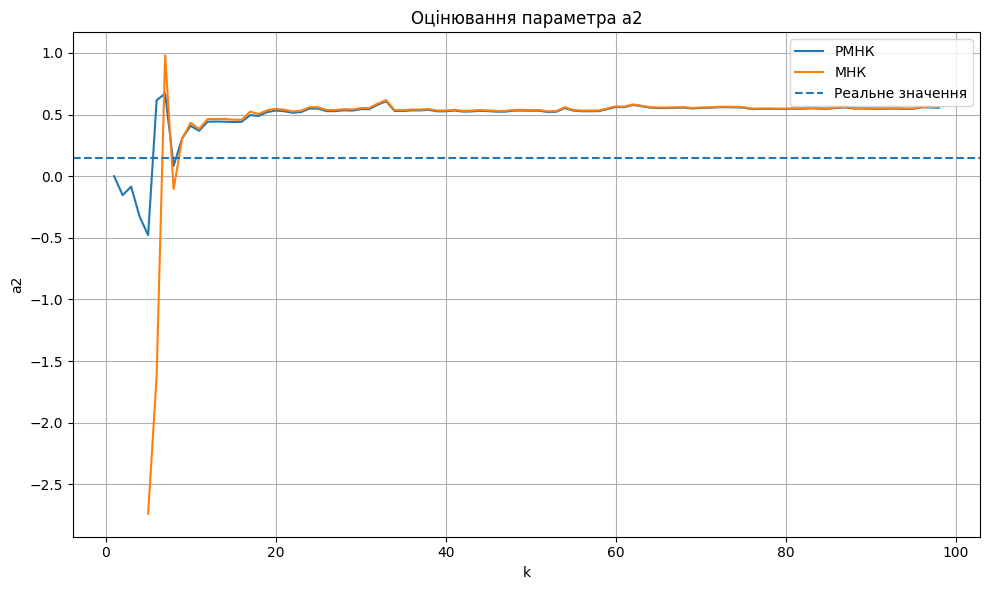

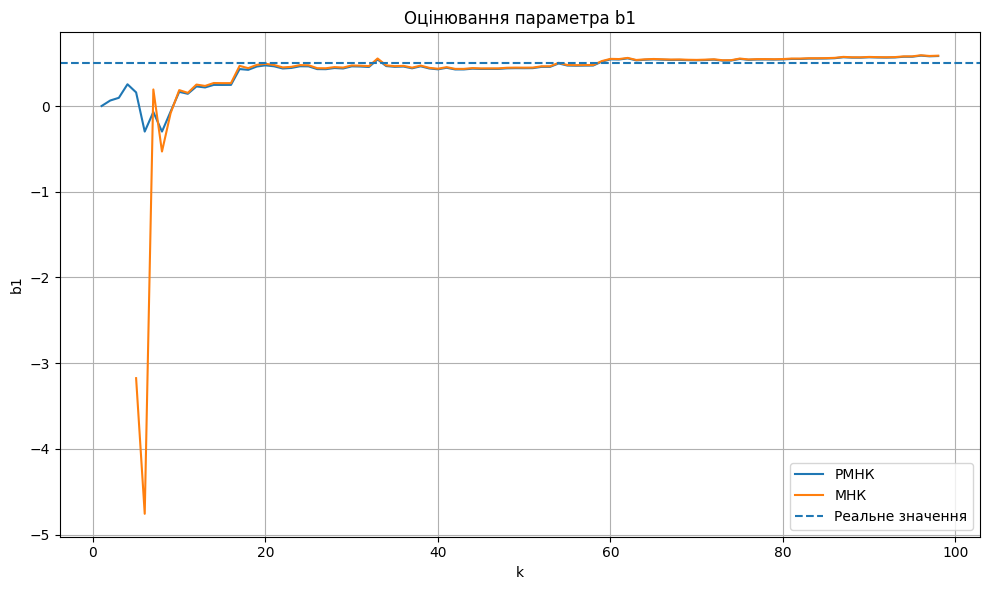

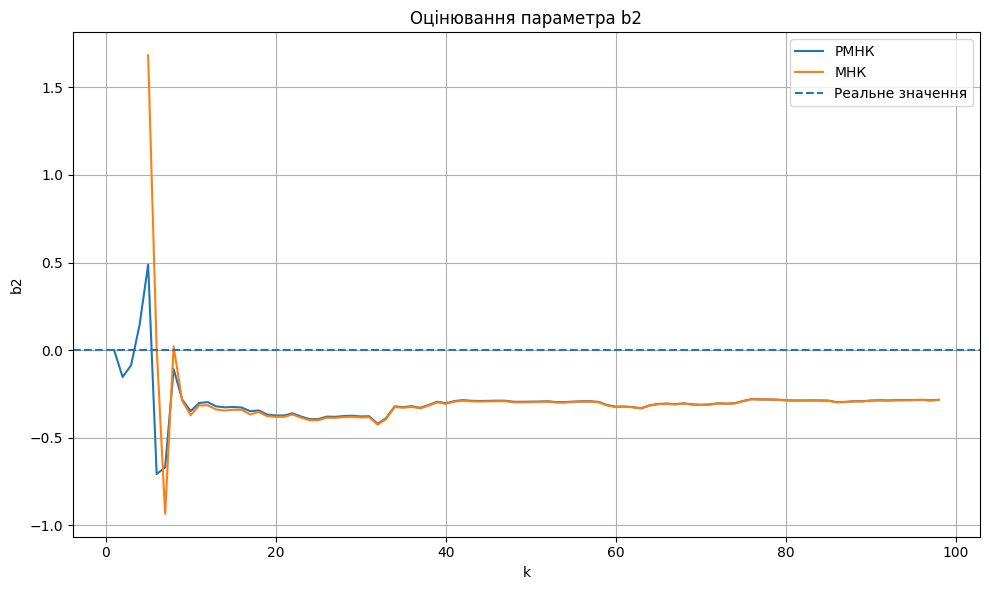

In [ ]:
for i, parameter_name in enumerate(parameter_names_22):

    plt.figure(figsize=(10, 6))

    # РМНК
    rls_history = rls_22["theta_history"]

    rls_k = np.arange(
        1,
        len(rls_history) + 1
    )

    plt.plot(
        rls_k,
        rls_history[:, i],
        label="РМНК"
    )

    # МНК
    ols_history_values = ols_22["theta_history"]
    ols_k = ols_22["k_history"]

    plt.plot(
        ols_k,
        ols_history_values[:, i],
        label="МНК"
    )

    # Реальне значення
    plt.axhline(
        y=true_theta_22[i],
        linestyle="--",
        label="Реальне значення"
    )

    plt.xlabel("k")
    plt.ylabel(parameter_name)
    plt.title(f"Оцінювання параметра {parameter_name}")

    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

Тепер графіки для S, R2, AIC

In [ ]:
model_names = [
    f"ARKS({result['p']},{result['q']})"
    for result in results
]

# МНК
ols_S = [result["S"] for result in results]
ols_R2 = [result["R2"] for result in results]
ols_AIC = [result["AIC"] for result in results]

# РМНК
rls_S = [result["S"] for result in r_results]
rls_R2 = [result["R2"] for result in r_results]
rls_AIC = [result["AIC"] for result in r_results]

In [ ]:
ols_R2

[np.float64(0.8947974068226571),
 np.float64(0.8985032206711561),
 np.float64(1.0053574878856697),
 np.float64(0.9258826722345386),
 np.float64(0.9311513321960825),
 np.float64(1.0039868053264702),
 np.float64(0.9454359637762291),
 np.float64(0.9445002170194978),
 np.float64(1.000000000008551)]

In [ ]:
rls_S

[np.float64(21.214438953619606),
 np.float64(20.00368913550923),
 np.float64(0.8994970501037363),
 np.float64(13.72232812975422),
 np.float64(10.864899504290326),
 np.float64(0.1883641541599562),
 np.float64(7.111802906524142),
 np.float64(6.814699867699833),
 np.float64(0.0001095942079811255)]

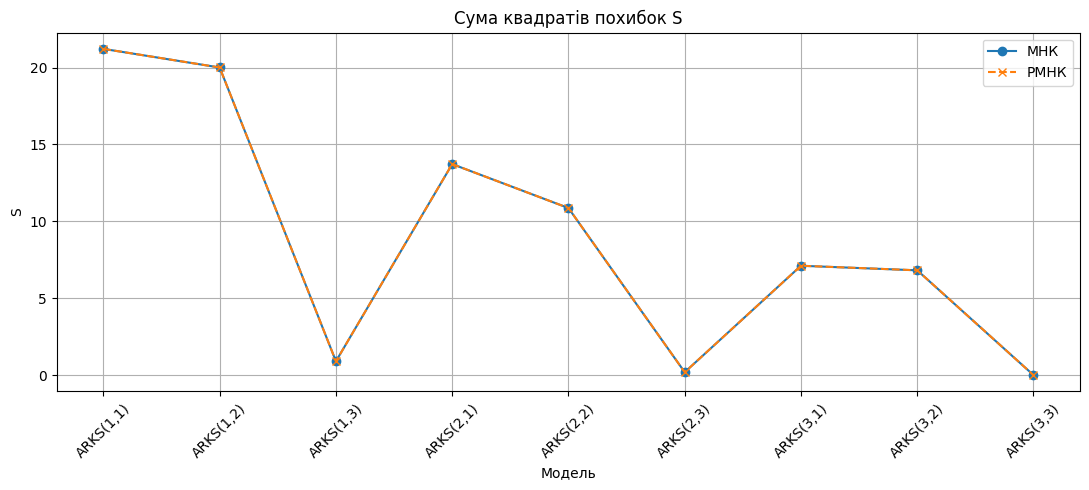

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(
    model_names,
    ols_S,
    marker="o",
    label="МНК"
)


plt.plot(
    model_names,
    rls_S,
    marker="x",
    label="РМНК",
    linestyle='--'
)

plt.xlabel("Модель")
plt.ylabel("S")
plt.title("Сума квадратів похибок S")

plt.xticks(rotation=45)
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

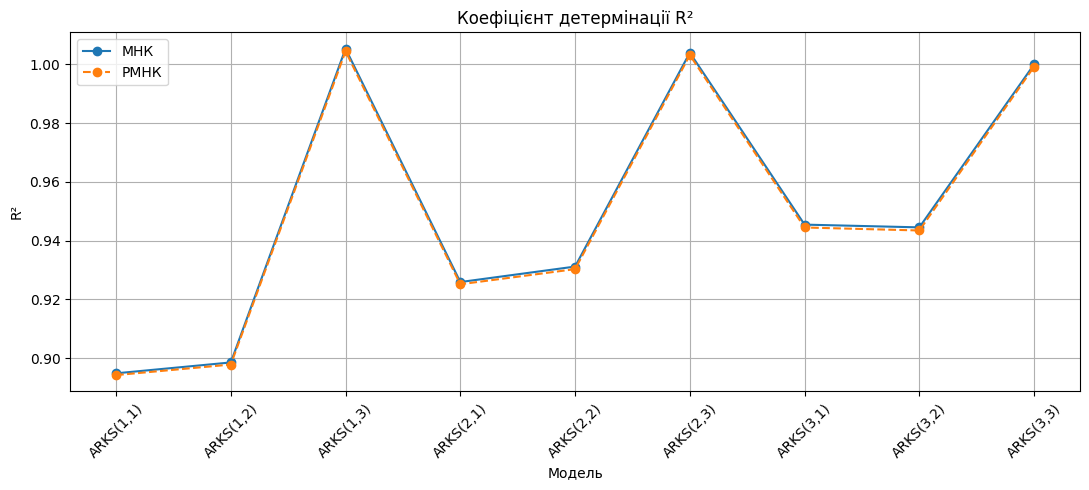

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(
    model_names,
    ols_R2,
    marker="o",
    label="МНК"
)

plt.plot(
    model_names,
    rls_R2,
    marker="o",
    label="РМНК",
    linestyle='--'
)

plt.xlabel("Модель")
plt.ylabel("R²")
plt.title("Коефіцієнт детермінації R²")

plt.xticks(rotation=45)
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

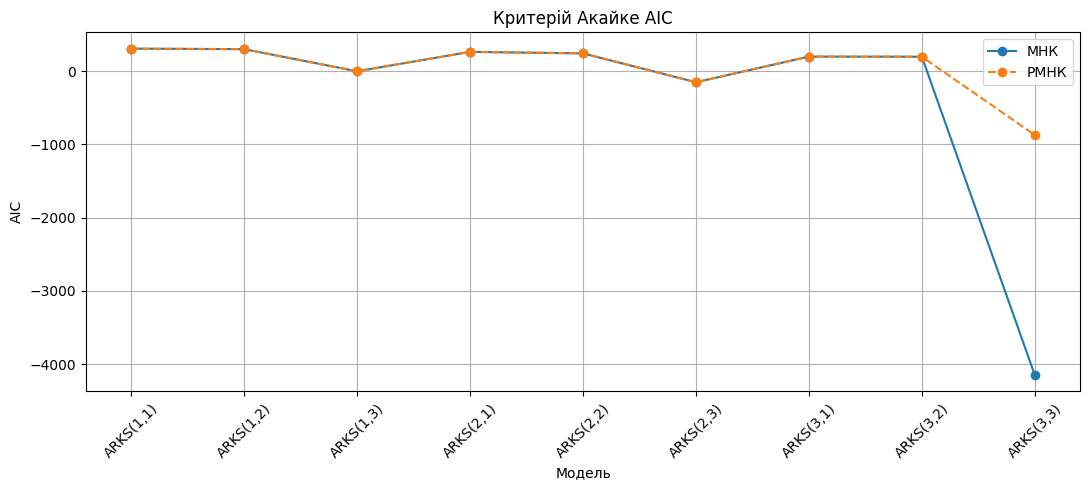

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(
    model_names,
    ols_AIC,
    marker="o",
    label="МНК"
)

plt.plot(
    model_names,
    rls_AIC,
    marker="o",
    label="РМНК",
    linestyle='--'
)

plt.xlabel("Модель")
plt.ylabel("AIC")
plt.title("Критерій Акайке AIC")

plt.xticks(rotation=45)
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Продемонструємо різницю між S^2 отриманих з допомогою НМК та РМНК

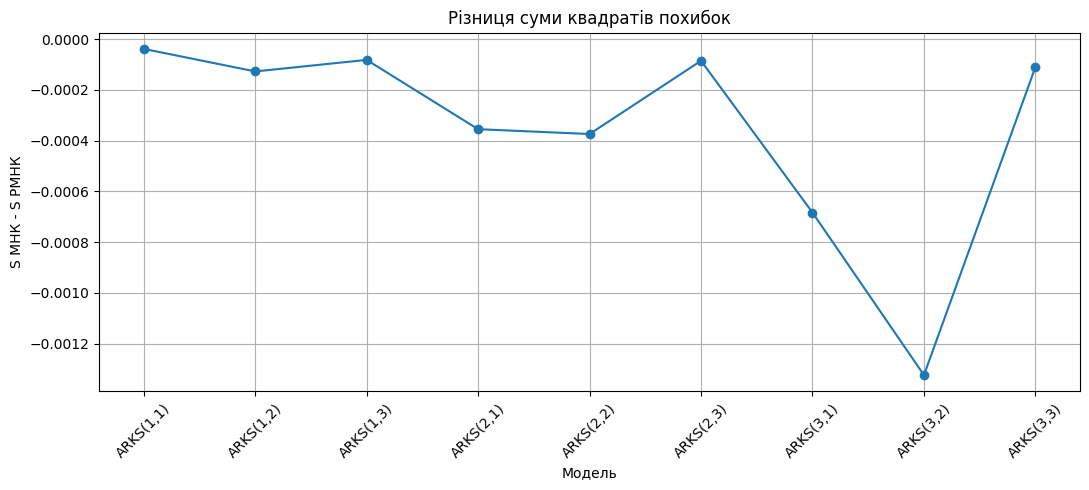

In [ ]:
S_difference = np.array(ols_S) - np.array(rls_S)
plt.figure(figsize=(11, 5))

plt.plot(
    model_names,
    S_difference,
    marker="o"
)

plt.xlabel("Модель")
plt.ylabel("S МНК - S РМНК")
plt.title("Різниця суми квадратів похибок")

plt.xticks(rotation=45)
plt.grid()

plt.tight_layout()
plt.show()

# Різниця між R2 НМК та РМНК

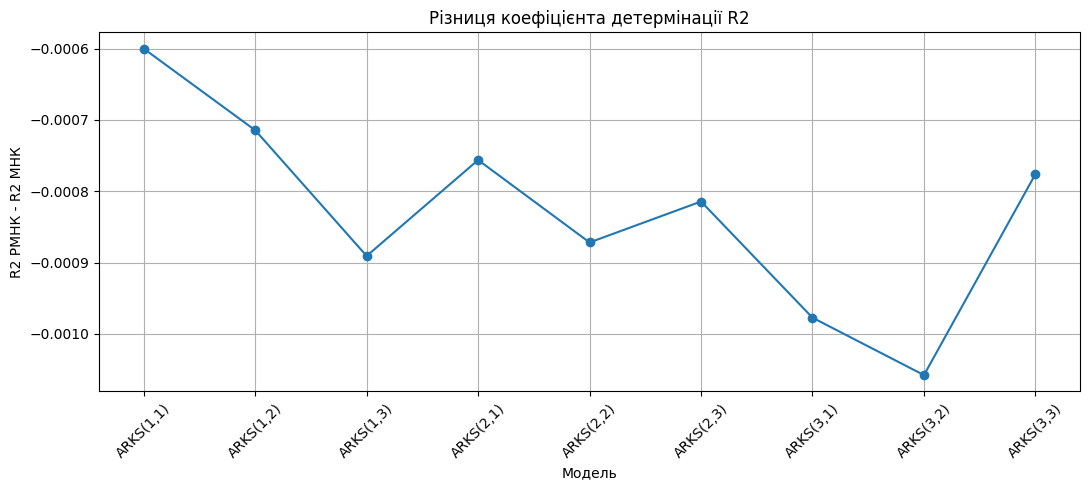

In [ ]:
R2_difference = np.array(rls_R2) - np.array(ols_R2)
plt.figure(figsize=(11, 5))

plt.plot(
    model_names,
    R2_difference,
    marker="o"
)

plt.xlabel("Модель")
plt.ylabel("R2 РМНК - R2 МНК")
plt.title("Різниця коефіцієнта детермінації R2")

plt.xticks(rotation=45)
plt.grid()

plt.tight_layout()
plt.show()

# Різниця між AIC НМК та РМНК

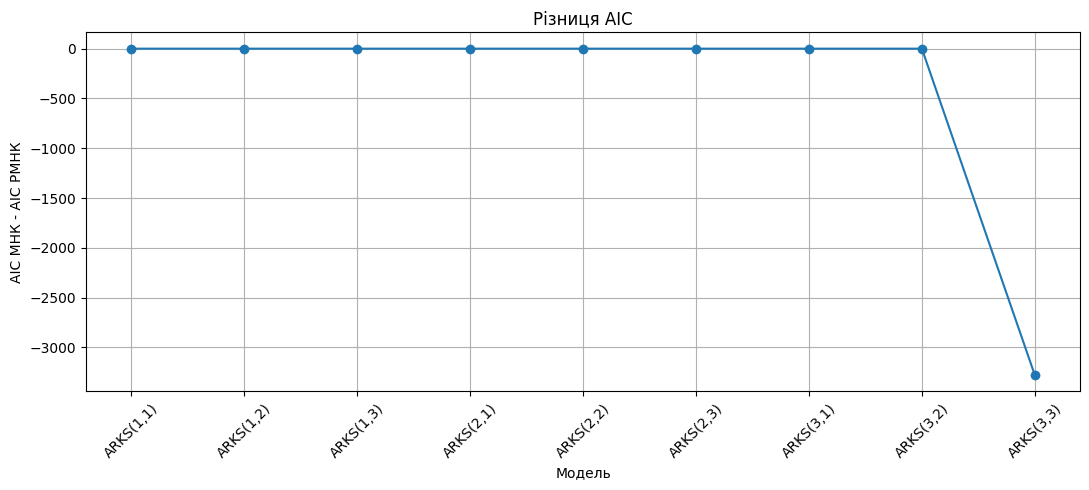

In [ ]:
AIC_difference = np.array(ols_AIC) - np.array(rls_AIC)
plt.figure(figsize=(11, 5))

plt.plot(
    model_names,
    AIC_difference,
    marker="o"
)

plt.xlabel("Модель")
plt.ylabel("AIC МНК - AIC РМНК")
plt.title("Різниця AIC")

plt.xticks(rotation=45)
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
#####
# порівняємо табличні данні
# 1) S
comparison_df.head()

,Model,S,R2,AIC,R S,R R2,R AIC
0,"ARKS(1,1)",21.214401,0.894797,308.413344,21.214439,0.894197,308.413521
1,"ARKS(1,2)",20.003562,0.898503,301.599216,20.003689,0.897789,301.599838
2,"ARKS(1,3)",0.899416,1.005357,-0.282964,0.899497,1.004467,-0.274192
3,"ARKS(2,1)",13.721974,0.925883,264.661850,13.722328,0.925126,264.664381
4,"ARKS(2,2)",10.864526,0.931151,243.779293,10.864900,0.930279,243.782662


In [ ]:
comparison_df["S- rS"] = comparison_df["S"] - comparison_df['R S']

In [ ]:
comparison_df["R2- R R2"] = comparison_df["R2"] - comparison_df['R R2']
comparison_df["AIC - R AIC"] = comparison_df["AIC"] - comparison_df['R AIC']

In [ ]:
comparison_df[['Model',"S- rS",	"R2- R R2",	"AIC - R AIC"]]

,Model,S- rS,R2- R R2,AIC - R AIC
0,"ARKS(1,1)",-0.000038,0.000600,-0.000177
1,"ARKS(1,2)",-0.000127,0.000714,-0.000622
2,"ARKS(1,3)",-0.000081,0.000891,-0.008772
3,"ARKS(2,1)",-0.000354,0.000756,-0.002531
4,"ARKS(2,2)",-0.000373,0.000872,-0.003369
5,"ARKS(2,3)",-0.000085,0.000814,-0.043725
6,"ARKS(3,1)",-0.000683,0.000977,-0.009317
7,"ARKS(3,2)",-0.001324,0.001058,-0.018842
8,"ARKS(3,3)",-0.000110,0.000776,-3277.824720
